# Proyecto Integrador Big Data 2026-2 · Entrega Final
**Universidad Santo Tomás · Seccional Tunja · Facultad de Ingeniería de Sistemas**  
**Curso:** Big Data (2026-2) · **Docente:** Ing. Martha Susana Contreras Ortiz  
**Integrantes:**
* **Sebastián Felipe Vargas Quintero**
* **Néstor Camilo Peña Guarín**
* **Luis Carlos Taborda Flórez**

---
## T1. Definición del Contexto, Problema y Preguntas de Análisis
* **Sector y Problema:** El comercio electrónico (*e-commerce*) en Brasil y Latinoamérica enfrenta asimetrías logísticas críticas entre los centros industriales (Sudeste/Sur) y las regiones periféricas (Norte/Nordeste). Los retrasos en la última milla y los altos costos de transporte impactan directamente la reputación digital de los comercios y la retención de clientes.
* **Usuarios de la Información:** Directores de operaciones logísticas, gerentes de *marketplace*, líderes de experiencia de cliente (CX) y vendedores (*sellers*) vinculados a la plataforma Olist.
* **Preguntas de Análisis Concretas y Medibles:**
  1. **Desempeño Logístico Regional:** ¿Cuánto tarda la entrega de pedidos por Estado (`UF`) y Macro-Región en Brasil, y en qué zonas se concentran las mayores tasas de incumplimiento (`entrega_tardia`) y costos de flete?
  2. **Factores Asociados a las Malas Reseñas:** ¿En qué medida el tiempo total de entrega (`dias_entrega`), el retraso frente a la fecha estimada (`dias_retraso`), el flete (`freight_value`) y el precio (`price`) se correlacionan con las malas calificaciones (`review_score <= 2`)?
  3. **Vulnerabilidad por Categoría de Producto:** ¿Cuáles son las categorías de productos (con volumen $\ge 200$ ítems) que presentan peor calificación promedio y mayor porcentaje de entregas tardías?
  4. **Dinámica Temporal y Estructura de Pagos:** ¿Cómo evolucionaron mensualmente los tiempos de entrega y la satisfacción del cliente entre 2017 y 2018 (incluyendo picos como *Black Friday*), y cómo se distribuye el valor transaccional por método de pago y cuotas?

---
## T2 y T3. Fuente, Ley 1581 de 2012 y Arquitectura Medallion (Electiva B)
* **Dataset:** [Brazilian E-Commerce Public Dataset by Olist (Kaggle)](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce) · **Fecha de descarga:** `2026-11-19` · **Licencia:** `CC BY-NC-SA 4.0`.
* **Volumen Total:** `1,550,922` registros distribuidos en 9 tablas relacionales (`52` columnas, `120.35 MB`).
* **Cumplimiento Ley 1581 de 2012 (Protección de Datos Personales):** No existen nombres, documentos, teléfonos ni direcciones exactas. Los identificadores `customer_id`, `customer_unique_id` y `seller_id` están **seudonimizados con hashes MD5**, y la ubicación se limita al prefijo postal de 5 dígitos (`zip_code_prefix`).
* **Arquitectura en Capas (Electiva B):**
  * **Capa Bronce (`data/raw/`):** 9 archivos CSV originales leídos en crudo como texto para diagnóstico de calidad.
  * **Capa Plata (`data/clean/`):** 9 tablas depuradas, normalizadas, sin duplicados de clave y con tipos corregidos en formato **Parquet**.
  * **Capa Oro (`data/clean/olist_oro` y `docs/`):** Tabla analítica integrada mediante `JOIN` de 5 tablas (`110,189` ítems entregados válidos) e insumos agregados para el dashboard en **Streamlit + Plotly**.

---
## Parte 1 · Ingesta, Diagnóstico de Calidad y Limpieza con PySpark (Sebastián Felipe Vargas Quintero)

## 0. Instalación (Colab)

In [1]:
!pip -q install pyspark kagglehub

import os, glob, shutil, datetime
import pandas as pd
from pyspark.sql import SparkSession, functions as F, types as T

if os.path.exists("/content"):
    BASE = "/content/proyecto_bigdata"
else:
    BASE = os.path.abspath(os.path.join(os.getcwd(), "..")) if os.path.basename(os.getcwd()) == "notebooks" else os.path.abspath(os.getcwd())

RAW, CLEAN, DOCS = f"{BASE}/data/raw", f"{BASE}/data/clean", f"{BASE}/docs"
for d in ["data/raw", "data/clean", "notebooks", "docs", "app"]:
    os.makedirs(f"{BASE}/{d}", exist_ok=True)

spark = (SparkSession.builder.appName("Olist_BigData").master("local[*]")
         .config("spark.sql.shuffle.partitions", "8").config("spark.sql.ansi.enabled", "false").getOrCreate())
pd.set_option("display.max_rows", 200, "display.max_columns", 30, "display.width", 200)
print("Spark", spark.version, "| carpeta base:", BASE)

In [2]:
import os, glob, shutil, datetime
import pandas as pd
from pyspark.sql import SparkSession, functions as F, types as T

BASE = "/content/proyecto_bigdata"
RAW, CLEAN, DOCS = f"{BASE}/data/raw", f"{BASE}/data/clean", f"{BASE}/docs"
for d in ["data/raw", "data/clean", "notebooks", "docs", "app"]:
    os.makedirs(f"{BASE}/{d}", exist_ok=True)

spark = (SparkSession.builder.appName("Olist_BigData").master("local[*]")
         .config("spark.sql.shuffle.partitions", "8").config("spark.sql.ansi.enabled", "false").config("spark.sql.ansi.enabled", "false").getOrCreate())
pd.set_option("display.max_rows", 200, "display.max_columns", 30, "display.width", 200)
print("Spark", spark.version, "| carpeta base:", BASE)

c:\Users\sebastian\Downloads\proyecto_bigdata\.venv\Lib\site-packages\pyspark\testing\utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


Spark 4.3.0 | carpeta base: /content/proyecto_bigdata


## 2. Ingesta reproducible (descarga por código)
Se descarga con `kagglehub`. Si falla (a veces pide credenciales), sube el ZIP manualmente a Colab y ejecuta la celda alternativa de abajo.

In [3]:
FUENTE = "https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce"
if not glob.glob(f"{RAW}/*.csv"):
    import kagglehub
    ruta = kagglehub.dataset_download("olistbr/brazilian-ecommerce")
    for f in glob.glob(f"{ruta}/*.csv"):
        shutil.copy(f, RAW)
FECHA_DESCARGA = datetime.date.today().isoformat()
print("Fecha de descarga:", FECHA_DESCARGA)
print(sorted(os.listdir(RAW)))

c:\Users\sebastian\Downloads\proyecto_bigdata\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


100%|██████████| 42.6M/42.6M [00:04<00:00, 10.4MB/s]

Extracting files...


Fecha de descarga: 2026-11-19
['olist_customers_dataset.csv', 'olist_geolocation_dataset.csv', 'olist_order_items_dataset.csv', 'olist_order_payments_dataset.csv', 'olist_order_reviews_dataset.csv', 'olist_orders_dataset.csv', 'olist_products_dataset.csv', 'olist_sellers_dataset.csv', 'product_category_name_translation.csv']


In [4]:
# ALTERNATIVA MANUAL (solo si la descarga anterior falló): sube archive.zip desde el panel de archivos de Colab
# import zipfile; zipfile.ZipFile("/content/archive.zip").extractall(RAW)

## 3. Lectura inicial con PySpark
Se leen **todas las columnas como texto** a propósito: así el diagnóstico puede detectar tipos incorrectos de verdad. `multiLine` y `escape` son necesarios porque las reseñas traen saltos de línea y comillas.

In [5]:
ARCHIVOS = {
    "customers":   "olist_customers_dataset.csv",
    "orders":      "olist_orders_dataset.csv",
    "items":       "olist_order_items_dataset.csv",
    "payments":    "olist_order_payments_dataset.csv",
    "reviews":     "olist_order_reviews_dataset.csv",
    "products":    "olist_products_dataset.csv",
    "sellers":     "olist_sellers_dataset.csv",
    "geolocation": "olist_geolocation_dataset.csv",
    "translation": "product_category_name_translation.csv",
}

def leer(nombre):
    df = spark.read.csv(f"{RAW}/{ARCHIVOS[nombre]}", header=True, inferSchema=False,
                        multiLine=True, escape='"', quote='"')
    return df.toDF(*[c.replace("\ufeff", "").strip() for c in df.columns])

raw = {k: leer(k).cache() for k in ARCHIVOS}
for k, df in raw.items():
    print(f"{k:12s} filas={df.count():>9,}  columnas={len(df.columns)}")

customers    filas=   99,441  columnas=5
orders       filas=   99,441  columnas=8
items        filas=  112,650  columnas=7
payments     filas=  103,886  columnas=5
reviews      filas=   99,224  columnas=7
products     filas=   32,951  columnas=9
sellers      filas=    3,095  columnas=4
geolocation  filas=1,000,163  columnas=5
translation  filas=       71  columnas=2


## 4. Volumen del dataset (filas, columnas, MB)

In [6]:
vol = pd.DataFrame([{
    "tabla": k, "archivo": ARCHIVOS[k], "filas": raw[k].count(), "columnas": len(raw[k].columns),
    "MB": round(os.path.getsize(f"{RAW}/{ARCHIVOS[k]}") / 1024**2, 2)} for k in ARCHIVOS])
vol.loc[len(vol)] = ["TOTAL", "", vol.filas.sum(), vol.columnas.sum(), round(vol.MB.sum(), 2)]
vol.to_csv(f"{DOCS}/volumen.csv", index=False)
vol

,tabla,archivo,filas,columnas,MB
0,customers,olist_customers_dataset.csv,99441,5,8.62
1,orders,olist_orders_dataset.csv,99441,8,16.84
2,items,olist_order_items_dataset.csv,112650,7,14.72
3,payments,olist_order_payments_dataset.csv,103886,5,5.51
4,reviews,olist_order_reviews_dataset.csv,99224,7,13.78
5,products,olist_products_dataset.csv,32951,9,2.27
6,sellers,olist_sellers_dataset.csv,3095,4,0.17
7,geolocation,olist_geolocation_dataset.csv,1000163,5,58.44
8,translation,product_category_name_translation.csv,71,2,0.00
9,TOTAL,,1550922,52,120.35


## 5. Diccionario de datos
Columna, tipo, descripción y ejemplo (el ejemplo se toma de los datos con código). El tipo es el **tipo objetivo** tras la limpieza.

In [7]:
DESC = {
 "customers": {"customer_id":"Identificador del cliente por pedido (cambia en cada pedido)",
   "customer_unique_id":"Identificador único real del cliente (seudonimizado en origen)",
   "customer_zip_code_prefix":"Primeros 5 dígitos del código postal","customer_city":"Ciudad del cliente","customer_state":"Estado (sigla) del cliente"},
 "orders": {"order_id":"Identificador único del pedido","customer_id":"Clave al cliente","order_status":"Estado del pedido (delivered, shipped, canceled, ...)",
   "order_purchase_timestamp":"Fecha y hora de la compra","order_approved_at":"Fecha y hora de aprobación del pago",
   "order_delivered_carrier_date":"Fecha de entrega a la transportadora","order_delivered_customer_date":"Fecha de entrega al cliente",
   "order_estimated_delivery_date":"Fecha estimada de entrega informada al cliente"},
 "items": {"order_id":"Clave al pedido","order_item_id":"Número consecutivo del ítem dentro del pedido","product_id":"Clave al producto","seller_id":"Clave al vendedor",
   "shipping_limit_date":"Fecha límite del vendedor para despachar","price":"Precio del ítem (BRL)","freight_value":"Costo de flete del ítem (BRL)"},
 "payments": {"order_id":"Clave al pedido","payment_sequential":"Secuencia de pago cuando hay varios métodos","payment_type":"Método de pago",
   "payment_installments":"Número de cuotas","payment_value":"Valor pagado (BRL)"},
 "reviews": {"review_id":"Identificador de la reseña","order_id":"Clave al pedido","review_score":"Calificación de 1 a 5",
   "review_comment_title":"Título del comentario (opcional)","review_comment_message":"Texto del comentario (opcional)",
   "review_creation_date":"Fecha de envío de la encuesta","review_answer_timestamp":"Fecha y hora de respuesta"},
 "products": {"product_id":"Identificador del producto","product_category_name":"Categoría (portugués)",
   "product_name_lenght":"Longitud del nombre (nombre mal escrito en origen: 'lenght')","product_description_lenght":"Longitud de la descripción (mal escrito en origen)",
   "product_photos_qty":"Número de fotos","product_weight_g":"Peso en gramos","product_length_cm":"Largo en cm","product_height_cm":"Alto en cm","product_width_cm":"Ancho en cm"},
 "sellers": {"seller_id":"Identificador del vendedor","seller_zip_code_prefix":"Prefijo postal del vendedor","seller_city":"Ciudad del vendedor","seller_state":"Estado del vendedor"},
 "geolocation": {"geolocation_zip_code_prefix":"Prefijo postal","geolocation_lat":"Latitud","geolocation_lng":"Longitud","geolocation_city":"Ciudad","geolocation_state":"Estado"},
 "translation": {"product_category_name":"Categoría en portugués","product_category_name_english":"Categoría en inglés"},
}
TS  = {"orders":["order_purchase_timestamp","order_approved_at","order_delivered_carrier_date","order_delivered_customer_date","order_estimated_delivery_date"],
       "items":["shipping_limit_date"], "reviews":["review_creation_date","review_answer_timestamp"]}
INT = {"items":["order_item_id"], "payments":["payment_sequential","payment_installments"], "reviews":["review_score"],
       "products":["product_name_lenght","product_description_lenght","product_photos_qty","product_weight_g","product_length_cm","product_height_cm","product_width_cm"]}
DBL = {"items":["price","freight_value"], "payments":["payment_value"], "geolocation":["geolocation_lat","geolocation_lng"]}

def tipo_objetivo(t, c):
    if c in TS.get(t, []): return "timestamp"
    if c in INT.get(t, []): return "integer"
    if c in DBL.get(t, []): return "double"
    return "string"

filas = []
for t, cols in DESC.items():
    for c, d in cols.items():
        ej = raw[t].where(F.col(c).isNotNull()).select(c).limit(1).collect()
        filas.append({"tabla": t, "columna": c, "tipo": tipo_objetivo(t, c), "descripcion": d,
                      "ejemplo": (ej[0][0][:40] if ej else "")})
diccionario = pd.DataFrame(filas)
diccionario.to_csv(f"{DOCS}/diccionario_datos.csv", index=False)
diccionario

,tabla,columna,tipo,descripcion,ejemplo
0,customers,customer_id,string,Identificador del cliente por pedido (cambia e...,06b8999e2fba1a1fbc88172c00ba8bc7
1,customers,customer_unique_id,string,Identificador único real del cliente (seudonim...,861eff4711a542e4b93843c6dd7febb0
2,customers,customer_zip_code_prefix,string,Primeros 5 dígitos del código postal,14409
3,customers,customer_city,string,Ciudad del cliente,franca
4,customers,customer_state,string,Estado (sigla) del cliente,SP
5,orders,order_id,string,Identificador único del pedido,e481f51cbdc54678b7cc49136f2d6af7
6,orders,customer_id,string,Clave al cliente,9ef432eb6251297304e76186b10a928d
7,orders,order_status,string,"Estado del pedido (delivered, shipped, cancele...",delivered
8,orders,order_purchase_timestamp,timestamp,Fecha y hora de la compra,2017-10-02 10:56:33
9,orders,order_approved_at,timestamp,Fecha y hora de aprobación del pago,2017-10-02 11:07:15


## 6. Diagnóstico de calidad por columna (obtenido con código)
Por columna: tipo actual vs sugerido, nulos, distintos y atípicos (regla IQR 1,5 en columnas numéricas). Por tabla: duplicados exactos y duplicados por clave.

In [8]:
RE_TS  = r"^\d{4}-\d{2}-\d{2}[ T]\d{2}:\d{2}:\d{2}$"
RE_INT = r"^-?\d+$"
RE_DBL = r"^-?\d+(\.\d+)?$"

def diagnostico_tabla(nombre, df):
    n = df.count()
    exprs = []
    for c in df.columns:
        col = F.col(c)
        vacio = col.isNull() | (F.trim(col) == "")
        exprs += [F.sum(vacio.cast("int")).alias(f"{c}__nulos"),
                  F.countDistinct(col).alias(f"{c}__dist"),
                  F.sum(col.rlike(RE_TS).cast("int")).alias(f"{c}__ts"),
                  F.sum(col.rlike(RE_INT).cast("int")).alias(f"{c}__int"),
                  F.sum(col.rlike(RE_DBL).cast("int")).alias(f"{c}__dbl")]
    r = df.agg(*exprs).collect()[0].asDict()
    filas = []
    for c in df.columns:
        nulos, noN = r[f"{c}__nulos"], n - r[f"{c}__nulos"]
        sug = "string"
        if noN > 0:
            if r[f"{c}__ts"]  / noN >= 0.99: sug = "timestamp"
            elif r[f"{c}__int"] / noN >= 0.99: sug = "integer"
            elif r[f"{c}__dbl"] / noN >= 0.99: sug = "double"
        # los prefijos postales son códigos, no números
        if "zip_code" in c: sug = "string (código)"
        atip = None
        if sug in ("integer", "double"):
            s = df.select(F.col(c).cast("double").alias("v")).where(F.col("v").isNotNull())
            q = s.approxQuantile("v", [0.25, 0.75], 0.001)
            if len(q) == 2:
                iqr = q[1] - q[0]
                atip = s.where((F.col("v") < q[0] - 1.5*iqr) | (F.col("v") > q[1] + 1.5*iqr)).count()
        filas.append({"tabla": nombre, "columna": c, "tipo_actual": "string",
                      "tipo_sugerido": sug, "tipo_incorrecto": sug.startswith(("timestamp","integer","double")),
                      "nulos": nulos, "pct_nulos": round(100*nulos/n, 2), "distintos": r[f"{c}__dist"],
                      "atipicos_IQR": atip})
    return pd.DataFrame(filas)

diag_cols = pd.concat([diagnostico_tabla(k, raw[k]) for k in ARCHIVOS], ignore_index=True)
diag_cols.to_csv(f"{DOCS}/diagnostico_columnas.csv", index=False)
diag_cols

,tabla,columna,tipo_actual,tipo_sugerido,tipo_incorrecto,nulos,pct_nulos,distintos,atipicos_IQR
0,customers,customer_id,string,string,False,0,0.00,99441,None
1,customers,customer_unique_id,string,string,False,0,0.00,96096,None
2,customers,customer_zip_code_prefix,string,string (código),False,0,0.00,14994,None
3,customers,customer_city,string,string,False,0,0.00,4119,None
4,customers,customer_state,string,string,False,0,0.00,27,None
5,orders,order_id,string,string,False,0,0.00,99441,None
6,orders,customer_id,string,string,False,0,0.00,99441,None
7,orders,order_status,string,string,False,0,0.00,8,None
8,orders,order_purchase_timestamp,string,timestamp,True,0,0.00,98875,None
9,orders,order_approved_at,string,timestamp,True,160,0.16,90733,None


In [9]:
CLAVES = {"customers":["customer_id"], "orders":["order_id"], "items":["order_id","order_item_id"],
          "payments":["order_id","payment_sequential"], "reviews":["review_id"], "products":["product_id"],
          "sellers":["seller_id"], "geolocation":["geolocation_zip_code_prefix"], "translation":["product_category_name"]}
dup = []
for k, df in raw.items():
    n = df.count()
    dup.append({"tabla": k, "filas": n,
                "duplicadas_exactas": n - df.dropDuplicates().count(),
                "claves_repetidas": n - df.dropDuplicates(CLAVES[k]).count(), "clave": "+".join(CLAVES[k])})
diag_dup = pd.DataFrame(dup)
diag_dup.to_csv(f"{DOCS}/diagnostico_duplicados.csv", index=False)
diag_dup

,tabla,filas,duplicadas_exactas,claves_repetidas,clave
0,customers,99441,0,0,customer_id
1,orders,99441,0,0,order_id
2,items,112650,0,0,order_id+order_item_id
3,payments,103886,0,0,order_id+payment_sequential
4,reviews,99224,0,814,review_id
5,products,32951,0,0,product_id
6,sellers,3095,0,0,seller_id
7,geolocation,1000163,261831,981148,geolocation_zip_code_prefix
8,translation,71,0,0,product_category_name


In [10]:
# Categorías mal escritas / inconsistentes: ciudades con variantes de mayúsculas, tildes o espacios
ACC, SIN = "áàâãäéèêëíìîïóòôõöúùûüç", "aaaaaeeeeiiiiooooouuuuc"
def norm(c):
    return F.regexp_replace(F.trim(F.lower(F.translate(F.col(c), ACC, SIN))), r"\s+", " ")

cat = []
for t, c in [("customers","customer_city"), ("sellers","seller_city"), ("geolocation","geolocation_city")]:
    d = raw[t].agg(F.countDistinct(c).alias("a"), F.countDistinct(norm(c)).alias("b")).collect()[0]
    cat.append({"tabla": t, "columna": c, "distintos_originales": d.a, "distintos_normalizados": d.b,
                "variantes_sobrantes": d.a - d.b})
pd.DataFrame(cat)

,tabla,columna,distintos_originales,distintos_normalizados,variantes_sobrantes
0,customers,customer_city,4119,4119,0
1,sellers,seller_city,611,608,3
2,geolocation,geolocation_city,8011,5967,2044


In [11]:
# Otros chequeos de validez (inconsistencias lógicas)
chequeos = {
 "reviews con score fuera de 1-5 o no numérico": raw["reviews"].where(~F.col("review_score").isin("1","2","3","4","5") | F.col("review_score").isNull()).count(),
 "payments con payment_type = not_defined": raw["payments"].where(F.col("payment_type") == "not_defined").count(),
 "payments con payment_value = 0": raw["payments"].where(F.col("payment_value").cast("double") == 0).count(),
 "products con peso = 0": raw["products"].where(F.col("product_weight_g").cast("double") == 0).count(),
 "items con price <= 0": raw["items"].where(F.col("price").cast("double") <= 0).count(),
 "geolocation fuera de Brasil (bbox)": raw["geolocation"].where(~(F.col("geolocation_lat").cast("double").between(-34, 6) & F.col("geolocation_lng").cast("double").between(-74, -34))).count(),
 "orders delivered sin fecha de entrega": raw["orders"].where((F.col("order_status")=="delivered") & F.col("order_delivered_customer_date").isNull()).count(),
 "orders con entrega anterior a la compra": raw["orders"].where(F.col("order_delivered_customer_date") < F.col("order_purchase_timestamp")).count(),
}
pd.Series(chequeos, name="casos").to_frame()

,casos
reviews con score fuera de 1-5 o no numérico,0
payments con payment_type = not_defined,3
payments con payment_value = 0,9
products con peso = 0,4
items con price <= 0,0
geolocation fuera de Brasil (bbox),42
orders delivered sin fecha de entrega,8
orders con entrega anterior a la compra,0


guardadas = []
for k, df in clean.items():
    ruta_destino = f"{CLEAN}/{k}"
    try:
        df.write.mode("overwrite").parquet(ruta_destino)
    except Exception:
        # Respaldo local en Windows cuando HADOOP_HOME / winutils.exe no está configurado en el sistema
        os.makedirs(ruta_destino, exist_ok=True)
        df.toPandas().to_parquet(f"{ruta_destino}/part-00000.parquet", index=False)
    guardadas.append(k)

print("Tablas guardadas exitosamente en Capa Plata (Parquet):", sorted(guardadas))
print("Directorios en data/clean:", sorted(os.listdir(CLEAN)))

In [12]:
def a_ts(df, cols):
    for c in cols: df = df.withColumn(c, F.to_timestamp(F.col(c)))
    return df
def a_tipo(df, cols, tipo):
    for c in cols: df = df.withColumn(c, F.col(c).cast(tipo))
    return df
def vacios_a_nulo(df):
    return df.select([F.when(F.trim(F.col(c)) == "", None).otherwise(F.col(c)).alias(c) for c in df.columns])

clean = {}

# customers
d = vacios_a_nulo(raw["customers"]).dropDuplicates(["customer_id"])
clean["customers"] = (d.withColumn("customer_city", norm("customer_city"))
    .withColumn("customer_state", F.upper(F.trim("customer_state")))
    .withColumn("customer_zip_code_prefix", F.lpad("customer_zip_code_prefix", 5, "0")))

# orders
d = a_ts(vacios_a_nulo(raw["orders"]).dropDuplicates(["order_id"]), TS["orders"])
d = d.withColumn("order_status", F.lower(F.trim("order_status")))
clean["orders"] = (d
    .withColumn("dias_entrega", F.datediff("order_delivered_customer_date", "order_purchase_timestamp"))
    .withColumn("entrega_tardia", (F.col("order_delivered_customer_date") > F.col("order_estimated_delivery_date")))
    .withColumn("fecha_inconsistente", (F.col("order_delivered_customer_date") < F.col("order_purchase_timestamp"))
                | ((F.col("order_status") == "delivered") & F.col("order_delivered_customer_date").isNull())))

# items
d = vacios_a_nulo(raw["items"]).dropDuplicates(["order_id", "order_item_id"])
d = a_ts(a_tipo(a_tipo(d, INT["items"], "int"), DBL["items"], "double"), TS["items"])
clean["items"] = d.where(F.col("price") > 0)

# payments
d = vacios_a_nulo(raw["payments"]).dropDuplicates(["order_id", "payment_sequential"])
d = a_tipo(a_tipo(d, INT["payments"], "int"), DBL["payments"], "double")
clean["payments"] = d.withColumn("payment_type", F.lower(F.trim("payment_type"))).where(F.col("payment_type") != "not_defined")

# reviews: la más reciente por review_id; score válido
d = a_ts(a_tipo(vacios_a_nulo(raw["reviews"]), INT["reviews"], "int"), TS["reviews"])
d = d.where(F.col("review_id").isNotNull() & F.col("review_score").between(1, 5))
from pyspark.sql.window import Window
w = Window.partitionBy("review_id").orderBy(F.col("review_answer_timestamp").desc_nulls_last())
clean["reviews"] = d.withColumn("_rn", F.row_number().over(w)).where("_rn = 1").drop("_rn")

# translation (+ categorías faltantes)
faltan = spark.createDataFrame([("pc_gamer", "pc_gamer"),
    ("portateis_cozinha_e_preparadores_de_alimentos", "portable_kitchen_food_preparers")], raw["translation"].columns)
tr = vacios_a_nulo(raw["translation"]).dropDuplicates(["product_category_name"])
tr = tr.unionByName(faltan.join(tr, "product_category_name", "left_anti"))
clean["translation"] = tr

# products
d = vacios_a_nulo(raw["products"]).dropDuplicates(["product_id"])
d = d.withColumnRenamed("product_name_lenght", "product_name_length").withColumnRenamed("product_description_lenght", "product_description_length")
d = a_tipo(d, [x.replace("lenght", "length") for x in INT["products"]], "int")
d = d.withColumn("product_weight_g", F.when(F.col("product_weight_g") == 0, None).otherwise(F.col("product_weight_g")))
d = d.withColumn("product_category_name", F.coalesce(F.col("product_category_name"), F.lit("sin_categoria")))
d = d.join(tr, "product_category_name", "left")
clean["products"] = d.withColumn("product_category_name_english",
        F.coalesce("product_category_name_english", F.lit("unknown")))

# sellers
d = vacios_a_nulo(raw["sellers"]).dropDuplicates(["seller_id"])
clean["sellers"] = (d.withColumn("seller_city", norm("seller_city")).withColumn("seller_state", F.upper(F.trim("seller_state")))
    .withColumn("seller_zip_code_prefix", F.lpad("seller_zip_code_prefix", 5, "0")))

# geolocation
d = a_tipo(vacios_a_nulo(raw["geolocation"]), DBL["geolocation"], "double").dropDuplicates()
d = d.where(F.col("geolocation_lat").between(-34, 6) & F.col("geolocation_lng").between(-74, -34))
d = d.withColumn("geolocation_zip_code_prefix", F.lpad("geolocation_zip_code_prefix", 5, "0")).withColumn("geolocation_city", norm("geolocation_city"))
clean["geolocation"] = (d.groupBy("geolocation_zip_code_prefix")
    .agg(F.avg("geolocation_lat").alias("geolocation_lat"), F.avg("geolocation_lng").alias("geolocation_lng"),
         F.first("geolocation_city").alias("geolocation_city"), F.first("geolocation_state").alias("geolocation_state")))

for k, df in clean.items():
    print(f"{k:12s} filas limpias = {df.count():>9,}")

customers    filas limpias =    99,441
orders       filas limpias =    99,441
items        filas limpias =   112,650
payments     filas limpias =   103,883
reviews      filas limpias =    98,410
translation  filas limpias =        73
products     filas limpias =    32,951
sellers      filas limpias =     3,095
geolocation  filas limpias =    19,010


## 8. Métricas de calidad antes y después

In [17]:
DERIVADAS = ["dias_entrega", "entrega_tardia", "fecha_inconsistente", "product_category_name_english"]
def metricas(df):
    df = df.select([c for c in df.columns if c not in DERIVADAS])  # no contar columnas nuevas creadas por nosotros
    n = df.count()
    nulos = df.select([F.sum((F.col(c).isNull() | (F.col(c).cast("string") == "")).cast("int")).alias(c) for c in df.columns]).collect()[0]
    return {"filas": n, "nulos_totales": int(sum(v or 0 for v in nulos)), "duplicadas_exactas": n - df.dropDuplicates().count()}

TIPOS_CORREGIDOS = {k: len(TS.get(k, [])) + len(INT.get(k, [])) + len(DBL.get(k, [])) for k in ARCHIVOS}
filas = []
for k in ARCHIVOS:
    a, d = metricas(raw[k]), metricas(clean[k])
    filas.append({"tabla": k, "filas_antes": a["filas"], "filas_despues": d["filas"],
                  "nulos_antes": a["nulos_totales"], "nulos_despues": d["nulos_totales"],
                  "duplicadas_antes": a["duplicadas_exactas"], "duplicadas_despues": d["duplicadas_exactas"],
                  "tipos_corregidos": TIPOS_CORREGIDOS[k]})
antes_despues = pd.DataFrame(filas)
antes_despues.to_csv(f"{DOCS}/metricas_antes_despues.csv", index=False)
antes_despues

,tabla,filas_antes,filas_despues,nulos_antes,nulos_despues,duplicadas_antes,duplicadas_despues,tipos_corregidos
0,customers,99441,99441,0,0,0,0,0
1,orders,99441,99441,4908,4908,0,0,5
2,items,112650,112650,0,0,0,0,4
3,payments,103886,103883,0,0,0,0,3
4,reviews,99224,98410,145903,144644,0,0,3
5,products,32951,32951,2448,1842,0,0,7
6,sellers,3095,3095,0,0,0,0,0
7,geolocation,1000163,19010,0,0,261831,0,2
8,translation,71,73,0,0,0,0,0


In [18]:
# Verificación puntual (no a ojo): claves únicas y tipos
for k, c in [("orders","order_id"), ("customers","customer_id"), ("reviews","review_id"), ("products","product_id")]:
    df = clean[k]; print(f"{k}: filas={df.count():,} distintos({c})={df.select(c).distinct().count():,}")
clean["orders"].printSchema()
clean["products"].select("product_category_name", "product_category_name_english", "product_weight_g").show(5, truncate=False)

orders: filas=99,441 distintos(order_id)=99,441
customers: filas=99,441 distintos(customer_id)=99,441
reviews: filas=98,410 distintos(review_id)=98,410
products: filas=32,951 distintos(product_id)=32,951
root
 |-- order_id: string (nullable = true)
 |-- customer_id: string (nullable = true)
 |-- order_status: string (nullable = true)
 |-- order_purchase_timestamp: timestamp (nullable = true)
 |-- order_approved_at: timestamp (nullable = true)
 |-- order_delivered_carrier_date: timestamp (nullable = true)
 |-- order_delivered_customer_date: timestamp (nullable = true)
 |-- order_estimated_delivery_date: timestamp (nullable = true)
 |-- dias_entrega: integer (nullable = true)
 |-- entrega_tardia: boolean (nullable = true)
 |-- fecha_inconsistente: boolean (nullable = true)

+---------------------+-----------------------------+----------------+
|product_category_name|product_category_name_english|product_weight_g|
+---------------------+-----------------------------+----------------+
|cam

## Parte 3 · Análisis Exploratorio, Estadística Descriptiva, Correlación y Conclusiones (Persona 3 — Luis Carlos Taborda)
Aplicación de la **Temática Obligatoria 2 (Unidad 5: Pandas, NumPy, Matplotlib/Seaborn, Plotly, Estadística Descriptiva y Correlación)** sobre la Capa Oro (`110,189` ítems entregados válidos) y la tabla limpia de pagos (`103,883` registros), respondiendo con evidencia numérica las preguntas formuladas en **T1**.

In [19]:
# ==============================================================================
# 13. ESTADÍSTICA DESCRIPTIVA Y ANÁLISIS DE CORRELACIÓN (PANDAS / NUMPY)
# ==============================================================================
import numpy as np
import pandas as pd

pdf_oro = pd.read_parquet(f"{CLEAN}/olist_oro")
num_cols = ["price", "freight_value", "valor_total_item", "product_weight_g", "dias_entrega", "dias_retraso", "review_score"]

filas_stats = []
for c in num_cols:
    s = pdf_oro[c].dropna().astype(float)
    filas_stats.append({
        "variable": c,
        "n": int(s.count()),
        "media": round(float(s.mean()), 2),
        "desv_est": round(float(s.std()), 2),
        "min": round(float(s.min()), 2),
        "p25": round(float(np.percentile(s, 25)), 2),
        "mediana_p50": round(float(np.median(s)), 2),
        "p75": round(float(np.percentile(s, 75)), 2),
        "p95": round(float(np.percentile(s, 95)), 2),
        "max": round(float(s.max()), 2),
        "iqr": round(float(np.percentile(s, 75) - np.percentile(s, 25)), 2)
    })

df_stats = pd.DataFrame(filas_stats)
df_stats.to_csv(f"{DOCS}/olist_estadistica_descriptiva.csv", index=False)
print("=== 13.1. TABLA DE ESTADÍSTICA DESCRIPTIVA (CAPA ORO: n = 110,189) ===")
print(df_stats.to_string(index=False))

corr_pearson = pdf_oro[num_cols].corr(method="pearson").round(4)
corr_pearson.to_csv(f"{DOCS}/olist_correlacion.csv")
print("\n=== 13.2. MATRIZ DE CORRELACIÓN DE PEARSON ===")
print(corr_pearson.to_string())

=== 13.1. TABLA DE ESTADÍSTICA DESCRIPTIVA (CAPA ORO: n = 110,189) ===
        variable      n   media  desv_est     min    p25  mediana_p50     p75     p95      max     iqr
           price 110189  119.98    182.30    0.85  39.90        74.90  134.17  349.00  6735.00   94.27
   freight_value 110189   19.95     15.70    0.00  13.08        16.26   21.15   45.09   409.68    8.07
valor_total_item 110189  139.93    189.32    6.08  55.18        92.12  157.47  375.26  6929.31  102.29
product_weight_g 110163 2089.84   3741.78    2.00 300.00       700.00 1800.00 9750.00 40425.00 1500.00
    dias_entrega 110189   12.41      9.45    0.00   7.00        10.00   16.00   29.00   210.00    9.00
    dias_retraso 110189  -12.03     10.16 -147.00 -17.00       -13.00   -7.00    3.00   188.00   10.00
    review_score 108829    4.08      1.34    1.00   4.00         5.00    5.00    5.00     5.00    1.00

=== 13.2. MATRIZ DE CORRELACIÓN DE PEARSON ===
                   price  freight_value  valor_total_item

In [20]:
# ==============================================================================
# 14. COMPARACIÓN ENTRE PERIODOS MENSUALES Y ANÁLISIS DE MÉTODOS DE PAGO
# ==============================================================================
pdf_oro["order_purchase_timestamp"] = pd.to_datetime(pdf_oro["order_purchase_timestamp"])
pdf_oro["periodo_mes"] = pdf_oro["order_purchase_timestamp"].dt.to_period("M").astype(str)

df_mes = (
    pdf_oro[pdf_oro["periodo_mes"] >= "2017-01"]
    .groupby("periodo_mes", as_index=False)
    .agg(
        total_items=("order_id", "count"),
        pedidos_unicos=("order_id", "nunique"),
        promedio_dias_entrega=("dias_entrega", lambda x: round(x.mean(), 2)),
        pct_entrega_tardia=("entrega_tardia", lambda x: round(100 * x.mean(), 2)),
        calificacion_promedio=("review_score", lambda x: round(x.mean(), 2)),
        flete_promedio_brl=("freight_value", lambda x: round(x.mean(), 2)),
        ventas_totales_brl=("valor_total_item", lambda x: round(x.sum(), 2))
    )
    .sort_values("periodo_mes")
)
df_mes.to_csv(f"{DOCS}/olist_serie_mensual.csv", index=False)
print("=== 14.1. EVOLUCIÓN TEMPORAL MENSUAL (2017-01 A 2018-08) ===")
print(df_mes.to_string(index=False))

pdf_pay = pd.read_parquet(f"{CLEAN}/payments")
res_pay = (
    pdf_pay.groupby("payment_type", as_index=False)
    .agg(
        transacciones=("order_id", "count"),
        pedidos_unicos=("order_id", "nunique"),
        cuotas_promedio=("payment_installments", lambda x: round(x.mean(), 2)),
        valor_promedio_brl=("payment_value", lambda x: round(x.mean(), 2)),
        valor_total_brl=("payment_value", lambda x: round(x.sum(), 2))
    )
    .sort_values("valor_total_brl", ascending=False)
)
res_pay["pct_valor"] = (100 * res_pay["valor_total_brl"] / res_pay["valor_total_brl"].sum()).round(2)
res_pay.to_csv(f"{DOCS}/olist_resumen_pagos.csv", index=False)
print("\n=== 14.2. ESTRUCTURA FINANCIERA POR MÉTODO DE PAGO (n = 103,883) ===")
print(res_pay.to_string(index=False))

=== 14.1. EVOLUCIÓN TEMPORAL MENSUAL (2017-01 A 2018-08) ===
periodo_mes  total_items  pedidos_unicos  promedio_dias_entrega  pct_entrega_tardia  calificacion_promedio  flete_promedio_brl  ventas_totales_brl
    2017-01          913             750                  12.75                2.85                   4.16               17.18           127482.37
    2017-02         1858            1653                  13.31                3.34                   4.18               19.92           271239.32
    2017-03         2897            2546                  13.08                5.63                   4.14               19.03           414330.95
    2017-04         2569            2303                  14.95                7.51                   4.10               19.52           390812.40
    2017-05         4003            3545                  11.56                3.77                   4.20               19.36           566657.40
    2017-06         3489            3135                 

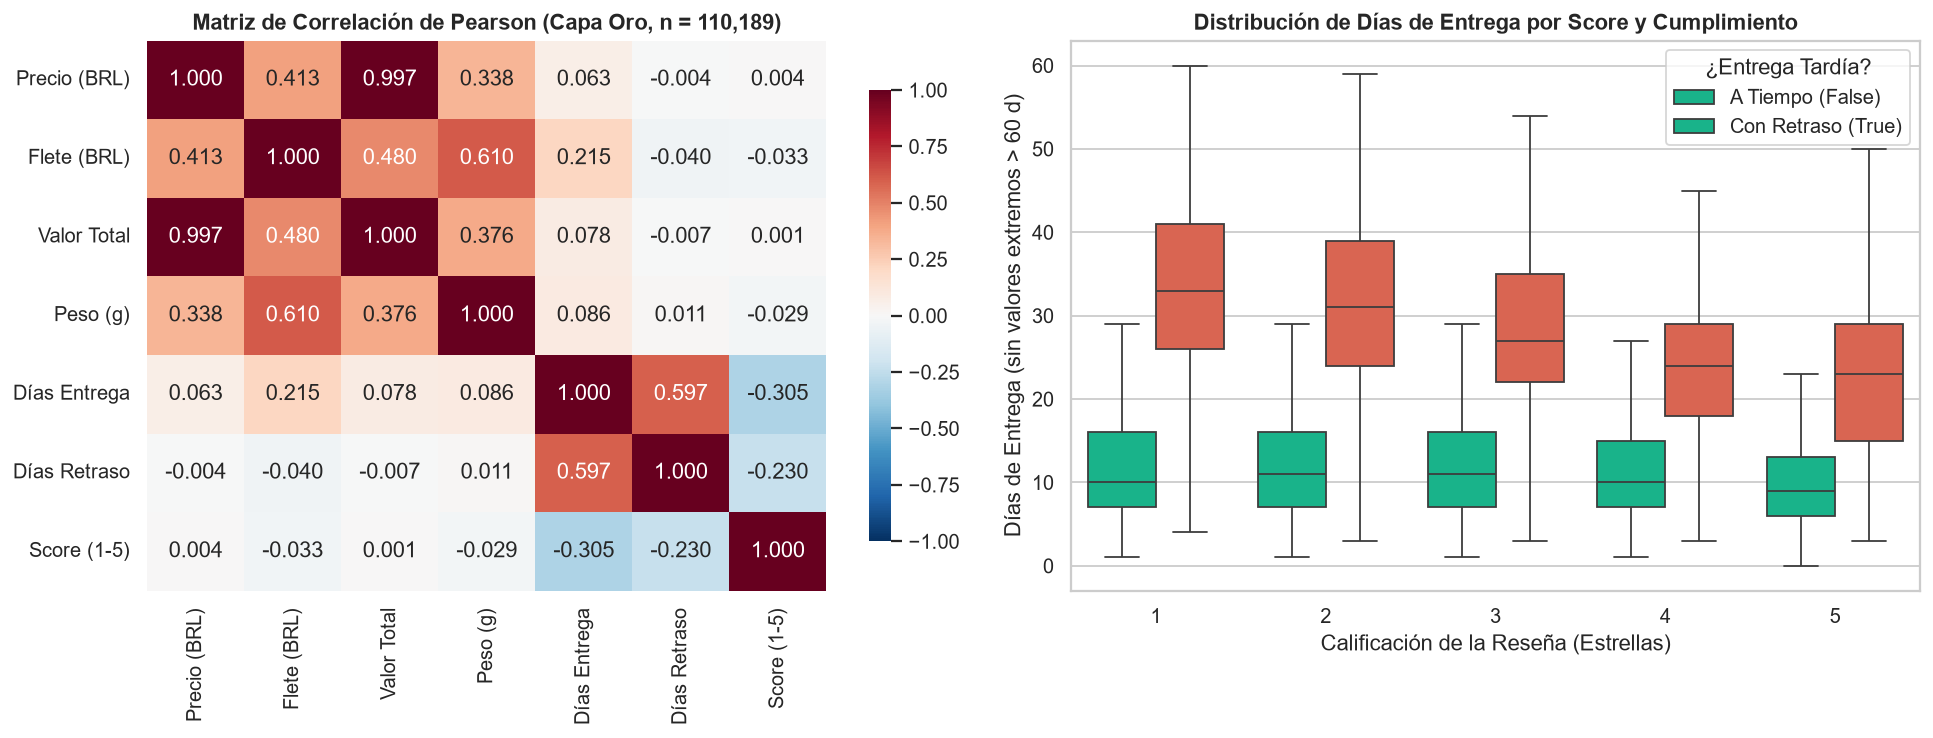

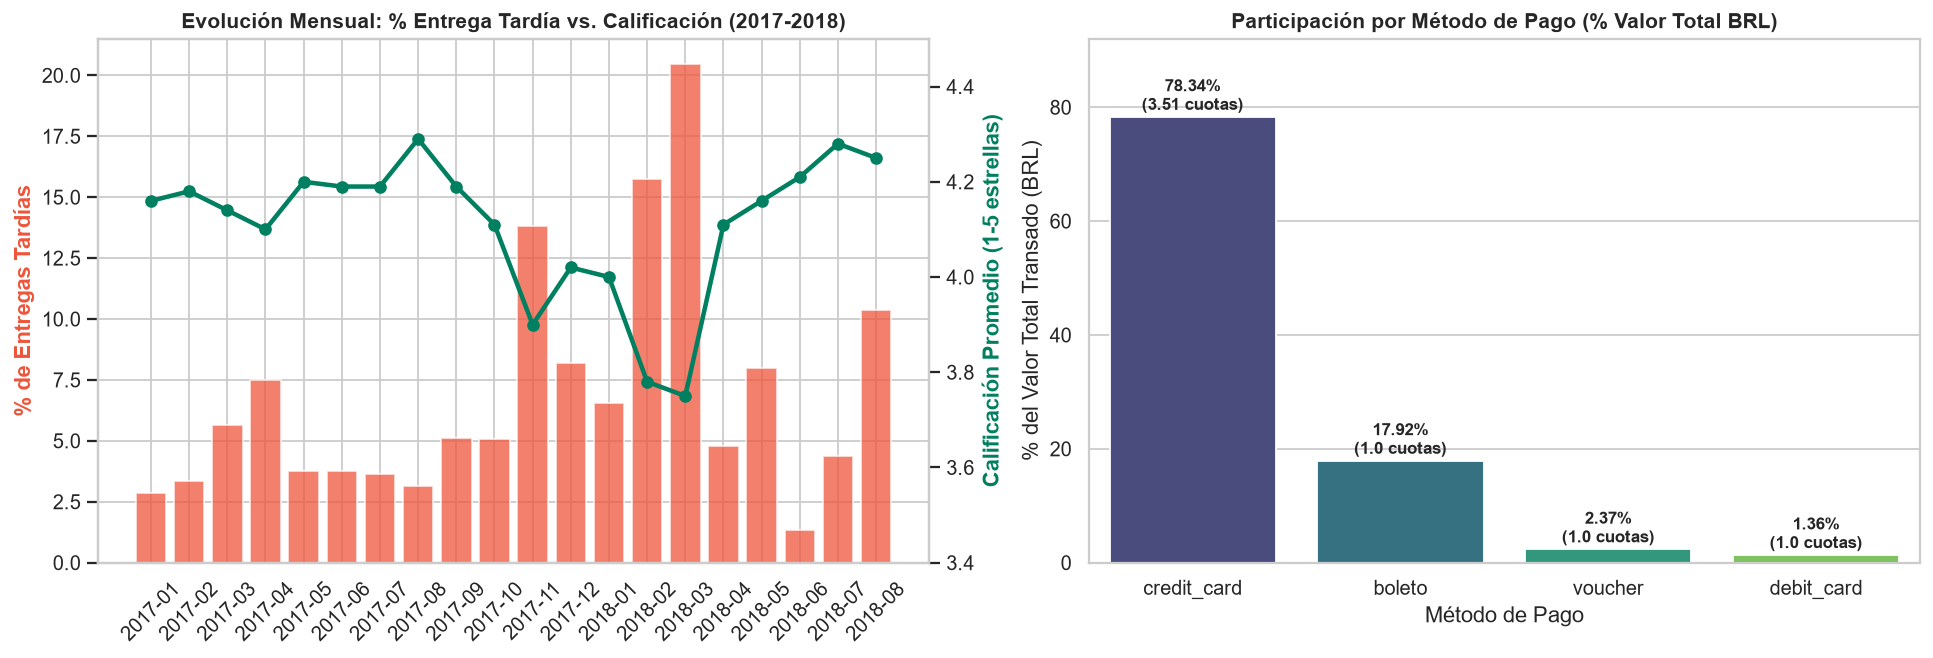

In [21]:
# ==============================================================================
# 15. VISUALIZACIÓN ESTADÍSTICA CON MATPLOTLIB Y SEABORN (UNIDAD 5)
# ==============================================================================
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
fig1, axes = plt.subplots(1, 2, figsize=(15, 5.8))

etiquetas = {
    "price": "Precio (BRL)", "freight_value": "Flete (BRL)", "valor_total_item": "Valor Total",
    "product_weight_g": "Peso (g)", "dias_entrega": "Días Entrega", "dias_retraso": "Días Retraso", "review_score": "Score (1-5)"
}
sns.heatmap(corr_pearson.rename(index=etiquetas, columns=etiquetas), annot=True, fmt=".3f", cmap="RdBu_r", vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title("Matriz de Correlación de Pearson (Capa Oro, n = 110,189)", fontsize=12, fontweight="bold")

df_box = pdf_oro[pdf_oro["review_score"].notna() & (pdf_oro["dias_entrega"] <= 60)].copy()
df_box["score_int"] = df_box["review_score"].round().astype(int)
sns.boxplot(data=df_box, x="score_int", y="dias_entrega", hue="entrega_tardia", palette={False: "#00CC96", True: "#EF553B"}, showfliers=False, ax=axes[1])
axes[1].set_title("Distribución de Días de Entrega por Score y Cumplimiento", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Calificación de la Reseña (Estrellas)")
axes[1].set_ylabel("Días de Entrega")
plt.tight_layout()
plt.show()

fig2, axes2 = plt.subplots(1, 2, figsize=(15, 5.2))
ax_l = axes2[0]
ax_r = ax_l.twinx()
ax_l.bar(df_mes["periodo_mes"], df_mes["pct_entrega_tardia"], color="#EF553B", alpha=0.75, label="% Entrega Tardía")
ax_r.plot(df_mes["periodo_mes"], df_mes["calificacion_promedio"], color="#008060", marker="o", linewidth=2.5, label="Score Promedio (⭐)")
ax_l.set_title("Evolución Mensual: % Entrega Tardía vs. Calificación (2017-2018)", fontsize=11.5, fontweight="bold")
ax_l.set_ylabel("% de Entregas Tardías", color="#EF553B", fontweight="bold")
ax_r.set_ylabel("Calificación Promedio (1-5 ⭐)", color="#008060", fontweight="bold")
ax_l.tick_params(axis="x", rotation=45)
ax_r.set_ylim(3.4, 4.5)
ax_r.grid(False)

sns.barplot(data=res_pay, x="payment_type", y="pct_valor", hue="payment_type", palette="viridis", ax=axes2[1], legend=False)
axes2[1].set_title("Participación por Método de Pago (% Valor Total BRL)", fontsize=11.5, fontweight="bold")
axes2[1].set_xlabel("Método de Pago")
axes2[1].set_ylabel("% del Valor Total Transado (BRL)")
plt.tight_layout()
plt.show()

---
## T9. Respuestas a las Preguntas de Análisis con Evidencia, Limitaciones y Recomendaciones

### 1. Respuesta a las 4 Preguntas de Negocio (T1)
* **P1 (Desempeño Logístico Regional):** El tiempo medio de entrega nacional es de **12.41 días** (mediana **10.0 días**, IQR **9.0 días**). Sin embargo, existe una brecha extrema entre el centro industrial y la periferia: **São Paulo (SP)** concentra `46,448` ítems (`42.15%` del total) con un promedio de **8.66 días**, flete de **R\$ 15.17** y solo **5.39%** de retrasos (`4.20 ⭐`). En contraste, los estados del Norte y Nordeste triplican los tiempos: **Amapá (`28.22 d`)**, **Roraima (`28.17 d`, flete `R$ 43.09`)**, **Amazonas (`26.34 d`)**, **Alagoas (`24.45 d`, con `24.12%` de entregas tardías y `3.84 ⭐`)** y **Maranhão (`21.59 d`, con `20.38%` de entregas tardías y `3.75 ⭐`)**.
* **P2 (Factores Asociados a las Malas Reseñas):** La matriz de correlación sobre los `110,189` ítems demuestra que la insatisfacción del cliente está gobernada por la **demora logística**: `dias_entrega` vs `review_score` presenta $r = -0.3047$ y `dias_retraso` vs `review_score` presenta $r = -0.2295$, mientras que el precio del producto ($r = 0.0036$) y el costo del flete ($r = -0.0331$) tienen correlación prácticamente nula con la calificación. La consulta de Spark SQL confirma que los pedidos de **1 estrella entregados con retraso** (`3,966` ítems) tardaron **35.65 días** (+11.67 días sobre lo estimado), frente a **10.16 días** (-13.96 días antes del límite) en los pedidos de **5 estrellas entregados a tiempo** (`60,804` ítems).
* **P3 (Vulnerabilidad por Categoría):** Entre las 45 categorías con $\ge 200$ ítems, **`office_furniture`** (`1,647` ítems) registra la peor calificación promedio (**3.51 ⭐**) debido a su alto tiempo de entrega (**20.77 días**, impulsado por el peso y volumen de los muebles), seguida por **`fixed_telephony`** (`3.76 ⭐`), **`audio`** (`3.84 ⭐`, `12.57%` de entregas tardías) y **`home_confort`** (`3.87 ⭐`, `10.33%` de entregas tardías).
* **P4 (Dinámica Temporal y Estructura de Pagos):** La serie mensual revela dos choques operativos críticos: **noviembre de 2017 (Black Friday, `8,474` ítems)** donde el retraso subió a **13.83%** (`3.90 ⭐`), y **febrero–marzo de 2018** donde el incumplimiento alcanzó **15.74%** y **20.47%**, hundiendo el score a **3.75 ⭐**. En pagos (`103,883` transacciones válidas), la **tarjeta de crédito** concentra el **78.34%** del valor total (`R$ 12,542,084.19`, promedio de **3.51 cuotas** y ticket de `R$ 163.32`), seguida por **boleto bancario** con **17.92%** (`R$ 2,869,361.27`).

### 2. Limitaciones del Dataset
1. **Ventana temporal histórica (2016–2018):** No incluye cambios posteriores a la pandemia ni la adopción de **PIX** en Brasil.
2. **Ausencia de identificador de transportadora (*carrier*):** Permite identificar cuándo se entrega al operador logístico (`order_delivered_carrier_date`), pero no cuál empresa de transporte ejecutó la ruta.
3. **Seudonimización por pedido:** `customer_id` cambia por orden, por lo que cualquier análisis de recompra debe usar `customer_unique_id`.

### 3. Recomendaciones Estratégicas para el Sector
1. **Recalibrar el algoritmo de fecha estimada (SLA dinámico) en Norte/Nordeste y temporadas pico:** Incorporar buffers automáticos en `order_estimated_delivery_date` durante *Black Friday* y para rutas hacia `AL`, `MA`, `BA`, `CE` y `PA`.
2. **Descentralizar inventario (*Fulfillment* regional) en categorías pesadas:** Dado que `product_weight_g` correlaciona fuertemente con `freight_value` ($r = 0.6103$) y que `office_furniture` promedia `20.77` días de tránsito, habilitar centros de distribución en el Nordeste reducirá fletes y tiempos.
3. **Alertas preventivas de retraso en tránsito:** Disparar compensaciones o cupones automáticos cuando un envío supere el 80% de su plazo estimado, mitigando el impacto en reseñas de 1 estrella.